# SoccerNet GSR baseline on Colab: midterm results

This notebook produces the midterm **baseline results (item 1)** and the **MMOCR jersey analysis (item 2a)**.

**Before running:**
1. Runtime > Change runtime type > **T4 GPU**.
2. Key icon in the left sidebar > add secrets `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`, `GITHUB_TOKEN`, and turn on **Notebook access** for each.
3. The PR adding `third_party/sn-gamestate` must be merged into `main`.

Then run the cells top to bottom. Skip the fallback cell unless the environment cell fails at the mmcv step.
Everything the report needs is copied to `MyDrive/gsr-results/midterm/` (cells 15, 19 and 20), so a disconnect costs at most the step that was running.
If your Drive is nearly full, set `SAVE_VIDEOS` and `SAVE_SLIM_STATE` to `False` in cell 1, and skip cell 21.

| Part | What it produces | Time |
|---|---|---|
| Setup (cells 1–7) | Environment + validation data | 25–35 min |
| **1b** own end-to-end run on 5 clips (cell 10) | Starts in the background; runs while you do the rest | ~2 h GPU |
| **1a** cached baseline on all 58 clips (cell 13) | GS-HOTA, DetA, AssA, per-clip table | ~5 min |
| **1c** no-jersey + oracle re-scores (cell 14) | The two jersey configurations | ~10 min |
| **2a** MMOCR tracklet accuracy (cell 15) | Accuracy + error breakdown + plot | ~5 min |
| **1c** calibration swap on 5 clips (cell 17) | TVCalib (cached) vs NBJW | ~15–25 min GPU |
| Tables + save (cells 19–20) | Summary tables for the report | ~5 min |

**One thing to know about calibration:** SoccerNet's cached state (Zenodo, April 2024) was produced with **TVCalib**, but this
sn-gamestate version runs **NBJW** calibration by default. A fresh run is therefore not directly comparable to the cached
numbers. Cell 17 re-runs only the calibration step on the cached state with NBJW, which gives (a) the calibration-swap
configuration and (b) a like-for-like reference for our own run.

In [1]:
# 1. Settings and secrets
import os
from google.colab import userdata

BUCKET = 'cmu-soccer-gsr-data'
S3_PREFIX = 'SoccerNetGS/gamestate-2024'   # folder holding train/valid/test/challenge .zip
AWS_REGION = 'us-east-2'                  # US East (Ohio)
SPLITS = ['valid']                        # add 'test' etc. only if needed (each zip is 5-10 GB)
REPO_URL = 'github.com/cmu-soccer-gsr/soccer-trajectory-prediction.git'

for k in ['AWS_ACCESS_KEY_ID', 'AWS_SECRET_ACCESS_KEY', 'GITHUB_TOKEN']:
    os.environ[k] = userdata.get(k)
os.environ['AWS_DEFAULT_REGION'] = AWS_REGION
os.environ['BUCKET'] = BUCKET
os.environ['S3_PREFIX'] = S3_PREFIX
os.environ['SPLITS'] = ' '.join(SPLITS)
os.environ['REPO_URL'] = REPO_URL
os.environ['REPO_DIR'] = '/content/soccer-trajectory-prediction'
os.environ['DATA_DIR'] = '/content/soccer-trajectory-prediction/data'
os.environ['PATH'] = '/root/.local/bin:' + os.environ['PATH']
# ---- Midterm additions: options you may want to change ----
N_CLIPS = 5                                     # clips for our own end-to-end run (first N, alphabetical)
SAVE_VIDEOS = True                              # copy our run's output videos to Drive (~100-300 MB)
SAVE_SLIM_STATE = True                          # keep the cached baseline state on Drive (~100 MB; else re-download next session)

# ---- Paths used by the midterm cells (exported so the %%bash cells can read them) ----
SG_DIR = os.environ['REPO_DIR'] + '/third_party/sn-gamestate'
DRIVE_ROOT = '/content/drive/MyDrive/gsr-results'
os.environ['SG_DIR'] = SG_DIR                                            # sn-gamestate code and its .venv
os.environ['TOOLS'] = os.environ['REPO_DIR'] + '/tools/gsr_tools.py'     # our helper script (written in cell 8)
os.environ['PY'] = SG_DIR + '/.venv/bin/python'    # helper runs in the sn-gamestate env
os.environ['GT_DIR'] = os.environ['DATA_DIR'] + '/SoccerNetGS/valid'     # ground-truth labels, one folder per clip
os.environ['RESULTS'] = DRIVE_ROOT + '/midterm'                          # everything for the report ends up here
os.environ['DRIVE_STATES'] = DRIVE_ROOT + '/states'                      # Drive copy of the cached baseline state
os.environ['SLIM'] = SG_DIR + '/states/baseline-valid-slim.pklz'         # local cached baseline state (cell 11)
os.environ['SAVE_VIDEOS'] = '1' if SAVE_VIDEOS else '0'
os.environ['SAVE_SLIM_STATE'] = '1' if SAVE_SLIM_STATE else '0'

# Mount Google Drive now, so results can be saved as soon as each step finishes
# (anything left only in /content is lost when the Colab session ends).
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(os.environ['RESULTS'], exist_ok=True)
os.makedirs(os.environ['DRIVE_STATES'], exist_ok=True)
print('Settings loaded.')

Mounted at /content/drive
Settings loaded.


In [2]:
# 2. Check GPU and free disk (need roughly 25 GB free for the valid split)
!nvidia-smi
!df -h /content

Wed Oct 21 20:41:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%%bash
# 3. Clone (or update) the team repo
set -e
if [ -d "$REPO_DIR/.git" ]; then
  cd "$REPO_DIR" && git pull "https://${GITHUB_TOKEN}@${REPO_URL}" main
else
  git clone "https://${GITHUB_TOKEN}@${REPO_URL}" "$REPO_DIR"
  cd "$REPO_DIR" && git remote set-url origin "https://${REPO_URL}"   # keep token out of .git/config
fi
ls "$REPO_DIR/third_party/sn-gamestate"
mkdir -p "$REPO_DIR/tools"   # folder for our helper script (cell 8)


ChallengeRules.md
examples_predictions
FAQ.md
images
LICENSE
plugins
poetry.lock
pretrained_models
pyproject.toml
README.md
sn_gamestate
uv.lock


Cloning into '/content/soccer-trajectory-prediction'...


In [4]:
%%bash
# 4. Build the baseline environment (10-20 min in a fresh session)
set -e

# Colab sets UV_SYSTEM_PYTHON=1, which makes uv install into Colab's own Python 3.13 instead of the venv
unset UV_SYSTEM_PYTHON UV_PYTHON

# Install uv if this session doesn't have it yet
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/install.sh | sh
export PATH="$HOME/.local/bin:/usr/local/bin:$PATH"

cd "$REPO_DIR/third_party/sn-gamestate"

# Create the Python 3.9 environment (skipped if it already exists in this session)
if [ ! -x .venv/bin/python ]; then
  uv venv --python 3.9 --seed
fi
source .venv/bin/activate

# Baseline + TrackLab + torch 1.13.1
uv pip install --python .venv/bin/python -e .

# Newer setuptools removed pkg_resources, which mmcv/mmengine still import
uv pip install --python .venv/bin/python "setuptools<70"

# Prebuilt mmcv 2.0.1 wheel for torch 1.13.1 + CUDA 11.7 (no compiling)
uv pip install --python .venv/bin/python mmcv==2.0.1 \
  -f https://download.openmmlab.com/mmcv/dist/cu117/torch1.13/index.html

# Verify
python -c "import sys, torch, mmcv; print('python', sys.version.split()[0], '| torch', torch.__version__, '| cuda', torch.version.cuda, '| gpu', torch.cuda.is_available(), '| mmcv', mmcv.__version__)"
pip show tracklab | grep -i '^version'

python 3.9.25 | torch 1.13.1+cu117 | cuda 11.7 | gpu True | mmcv 2.0.1
Version: 1.3.24


Using CPython 3.9.25
Creating virtual environment with seed packages at: .venv
 + packaging==26.3
 + pip==26.0.1
 + setuptools==82.0.1
 + wheel==0.48.0
Activate with: source .venv/bin/activate
Resolved 193 packages in 10.02s
Prepared 189 packages in 22.79s
Uninstalled 1 package in 0.90ms
Installed 190 packages in 271ms
 + absl-py==2.3.1
 + accelerate==1.2.1
 + aiohappyeyeballs==2.6.1
 + aiohttp==3.13.5
 + aiosignal==1.4.0
 + albumentations==1.4.3
 + annotated-doc==0.0.5
 + annotated-types==0.7.0
 + antlr4-python3-runtime==4.9.3
 + anyio==4.12.1
 + arrow==1.4.0
 + async-timeout==5.0.1
 + attrs==26.1.0
 + babel==2.18.0
 + backoff==2.2.1
 + beautifulsoup4==4.15.0
 + blessed==1.52.0
 + certifi==2026.10.19
 + charset-normalizer==3.5.2
 + click==8.1.8
 + colorama==0.4.6
 + coloredlogs==15.0.1
 + contourpy==1.3.0
 + croniter==1.4.1
 + cycler==0.12.1
 + cython==3.3.0
 + dateutils==0.6.12
 + deepdiff==7.0.1
 + distinctipy==1.3.4
 + easyocr==1.7.1
 + editor==1.6.6
 + eval-type-backport==0.4.0
 +

**Fallback (only if cell 4 failed at the mmcv step):** installs a torch/CUDA combination that has a prebuilt mmcv 2.0.1 wheel.

In [ ]:
%%bash
# 4b. FALLBACK - run only if cell 4 failed
set -e
cd "$REPO_DIR/third_party/sn-gamestate"
uv pip install torch==1.13.1 torchvision==0.14.1 --extra-index-url https://download.pytorch.org/whl/cu117
uv pip install mmcv==2.0.1 -f https://download.openmmlab.com/mmcv/dist/cu117/torch1.13/index.html
source .venv/bin/activate
python -c "import torch, mmcv; print('torch', torch.__version__, '| gpu', torch.cuda.is_available(), '| mmcv', mmcv.__version__)"

In [5]:
%%bash
# 5. Download and unzip the selected splits from S3 (zip is deleted after unzipping to save disk)
set -e
pip install -q awscli
mkdir -p "$DATA_DIR/SoccerNetGS/zips"
cd "$DATA_DIR/SoccerNetGS"
for s in $SPLITS; do
  if [ -d "$s" ] && [ -n "$(ls -A "$s")" ]; then echo "$s already present, skipping"; continue; fi
  echo "Downloading $s.zip ..."
  aws s3 cp "s3://$BUCKET/$S3_PREFIX/$s.zip" "zips/$s.zip"
  echo "Unzipping $s.zip ..."
  unzip -q "zips/$s.zip" -d "$s"
  rm "zips/$s.zip"
done
rmdir zips 2>/dev/null || true
for s in train valid test challenge; do mkdir -p "$s"; done   # empty placeholders for splits not downloaded
du -sh *
df -h /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 105.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 45.9 MB/s eta 0:00:00
download: s3://cmu-soccer-gsr-data/SoccerNetGS/gamestate-2024/valid.zip to zips/valid.zip
Unzipping valid.zip ...
4.0K	challenge
4.0K	test
4.0K	train
12G	valid
Filesystem      Size  Used Avail Use% Mounted on
overlay         236G   60G  176G  26% /


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [6]:
# 6. Verify the data layout and dataset version (should be 1.3)
import json, glob, os
root = os.environ['DATA_DIR'] + '/SoccerNetGS/valid'
labels = sorted(glob.glob(root + '/*/Labels-GameState.json'))
print(len(labels), 'validation clips found')
if labels:
    print('example:', labels[0])
    print('dataset version:', json.load(open(labels[0]))['info']['version'])
else:
    print('No clips found directly under valid/. Nested folders found:')
    print(glob.glob(root + '/**/Labels-GameState.json', recursive=True)[:3])

58 validation clips found
example: /content/soccer-trajectory-prediction/data/SoccerNetGS/valid/SNGS-021/Labels-GameState.json
dataset version: 1.3


In [7]:
%%bash
# 7. Remove the empty train/test/challenge placeholder folders
cd "$DATA_DIR/SoccerNetGS"
for s in train test challenge; do [ -d "$s" ] && [ -z "$(ls -A "$s")" ] && rmdir "$s" && echo "removed empty $s"; done; true
ls

removed empty train
removed empty test
removed empty challenge
valid


---
## Midterm experiments

**How this section is organised.** Re-running the full pipeline is slow (~20-25 min per clip), so almost everything here works on
a *tracker state*: a saved `.pklz` file holding every detection, track id, pitch position, team, role and jersey number the
pipeline produced. Changing one column of a state and re-scoring takes about a minute, and no models run.

| Cell | Item | What happens | Uses |
|---|---|---|---|
| 8–9 | setup | Write the helper script and a TrackLab launcher | |
| 10 | 1b | **Start** our own end-to-end run on 5 clips in the background | GPU, ~2 h |
| 11–12 | | Get SoccerNet's cached baseline state and check its columns | |
| 13 | 1a | Score the cached state on all 58 clips | CPU |
| 14 | 1c | No-jersey and oracle copies of the state, scored on all 58 clips | CPU |
| 15 | 2a | MMOCR tracklet accuracy and error breakdown | CPU |
| 16 | | **Wait** for the background run to finish | |
| 17–18 | 1c, 1b | Calibration swap; cached state scored on the same 5 clips | GPU, ~20 min |
| 19–20 | | Tables for the report; save everything to Drive | |

Cells 11–15 run while the GPU run is going. If Colab warns about RAM, run cell 16 (wait) first and come back to 13–15.

Every TrackLab run writes to its own folder `outputs/runs/<name>/` and logs to `outputs/logs/<name>.log`, so nothing overwrites anything else.

**8. Write the helper script** `tools/gsr_tools.py`. It has four commands, all used below:
`inspect` (show what is in a state), `edit` (make the no-jersey and oracle copies), `jersey-acc` (item 2a)
and `results` (collect scores into tables). Each command is documented at the top of the file.
If the file is already committed to the repo, this cell just overwrites it with the same code.

In [8]:
%%writefile /content/soccer-trajectory-prediction/tools/gsr_tools.py
"""Helpers for the SoccerNet-GSR midterm experiments (Group 15).

What this script does
---------------------
It works on TrackLab "tracker states" (.pklz files): the saved output of the
sn-gamestate pipeline. Because the state already holds every detection, track
ID, pitch position, team, role and jersey number, we can change one column
(the jersey numbers) and re-score GS-HOTA in about a minute, without re-running
any of the models. This is the "cached-state" approach from the TA feedback.

Commands
--------
inspect     Print what is inside a .pklz state (files, columns, example values).
            Run this first on any new state, to confirm the column names.
edit        Write a copy of a state with the jersey numbers changed:
              nojersey      every jersey set to null (floor: no jersey reader)
              oracle        each predicted tracklet gets the true number of the
                            ground-truth player it overlaps most (ceiling for a
                            reader that outputs one number per tracklet)
              oracle-frame  each detection gets the true number of the player it
                            matches in that frame (also undoes ID switches)
jersey-acc  Tracklet-level accuracy of the state's jersey reader (MMOCR in the
            baseline), with an error breakdown (item 2a of the midterm plan).
results     Collect GS-HOTA / DetA / AssA (overall and per clip) from one or more
            TrackLab run folders into tables for the report.

Examples (from the sn-gamestate folder, using its virtualenv):
    .venv/bin/python tools/gsr_tools.py inspect states/baseline-valid-slim.pklz
    .venv/bin/python tools/gsr_tools.py edit states/baseline-valid-slim.pklz \\
        states/edited/oracle.pklz --mode oracle --gt-dir data/SoccerNetGS/valid
    .venv/bin/python tools/gsr_tools.py jersey-acc states/baseline-valid-slim.pklz \\
        --gt-dir data/SoccerNetGS/valid --out-dir results/jersey --plot
    .venv/bin/python tools/gsr_tools.py results outputs/runs/cached_58 outputs/runs/oracle_58

Why the sn-gamestate virtualenv (Python 3.9, pandas 2.2): the state files are
pandas pickles, so we read and write them with the same pandas version TrackLab
uses. Writing them with a different pandas version could make them unreadable.

Key terms
---------
detection   One player box in one frame.
tracklet    The chain of detections the tracker links together as one player
            (same track_id). One real player can be split into several tracklets.
GT          Ground truth: the human labels in each clip's Labels-GameState.json.

How the GS-HOTA evaluator treats jerseys (sn-trackeval 0.4.0), which this
script mirrors:
  * it scores the tracklet-level column `jersey_number` (the result of voting
    over the per-frame reads in `jersey_number_detection`);
  * jerseys are compared as strings with ==, so "7" != 7 and "07" != "7";
  * jerseys only count for role == "player" (not goalkeepers or referees);
  * null vs null counts as a match (no number visible, none predicted).
"""
import argparse
import glob
import json
import os
import pickle
import sys
import zipfile
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment  # Hungarian algorithm for matching

# Order matters: the dataset encodes the split as a digit in image ids
# (train=1, valid=2, test=3, challenge=4).
SPLITS = ["train", "valid", "test", "challenge"]


# ==========================================================================
# Small utilities
# ==========================================================================
def is_null(x):
    """True for None and NaN; False for anything else (including strings)."""
    if x is None:
        return True
    try:
        return bool(pd.isna(x))
    except (TypeError, ValueError):  # pd.isna on lists/dicts returns arrays
        return False


def jersey_str(x):
    """Normalise a jersey value to the string form the evaluator compares.

    7 / 7.0 / "7" -> "7"; null -> None. Other strings are kept as-is, so "07"
    stays "07" (the evaluator would also treat it as different from "7").
    """
    if is_null(x):
        return None
    if isinstance(x, (int, np.integer)):
        return str(int(x))
    if isinstance(x, (float, np.floating)):
        return str(int(x)) if float(x).is_integer() else str(x)
    s = str(x).strip()
    return s if s != "" else None


def pitch_xy(b):
    """Return the player's position on the pitch, in meters, or None.

    `bbox_pitch` is a dict of the box's bottom edge projected onto the pitch.
    GS-HOTA uses the bottom-middle point (where the feet are), so we do too.
    """
    if isinstance(b, dict):
        x, y = b.get("x_bottom_middle"), b.get("y_bottom_middle")
        if x is not None and y is not None and np.isfinite(x) and np.isfinite(y):
            return float(x), float(y)
    return None


def video_key(v):
    """Common key for a clip, whatever form its id comes in.

    The state names clips '021', the data folders are 'SNGS-021', and some
    places use 21. All of these map to '021'.
    """
    s = str(v).split("-")[-1]
    return s.zfill(3) if s.isdigit() else s


# ==========================================================================
# Reading and writing tracker states (.pklz)
#
# A .pklz file is a zip archive with, per clip:
#   <clip>.pkl        DataFrame of predicted detections (one row per box)
#   <clip>_image.pkl  DataFrame of per-frame info (camera parameters, etc.)
# plus summary.json listing the columns. We only ever edit <clip>.pkl.
# ==========================================================================
def list_state_videos(state_path):
    """Clip ids stored in a state, e.g. ['021', '022', ...]."""
    with zipfile.ZipFile(state_path) as zf:
        names = zf.namelist()
    return sorted(n[:-4] for n in names
                  if n.endswith(".pkl") and not n.endswith("_image.pkl"))


def iter_state_detections(state_path, videos=None):
    """Yield (clip_id, detections DataFrame) one clip at a time.

    Reading one clip at a time keeps memory low, which matters on Colab when
    the long end-to-end run is using the same machine. `videos` optionally
    restricts which clips are read (a set of video_key values).
    """
    with zipfile.ZipFile(state_path) as zf:
        names = sorted(n for n in zf.namelist()
                       if n.endswith(".pkl") and not n.endswith("_image.pkl"))
        for name in names:
            vid = name[:-4]
            if videos is not None and video_key(vid) not in videos:
                continue
            with zf.open(name, force_zip64=True) as f:
                yield vid, pd.read_pickle(f)


def write_edited_state(src, dst, edit_fn, videos=None):
    """Copy a state to `dst`, passing each clip's detections through edit_fn.

    edit_fn(clip_id, df) must return the edited DataFrame. Everything else
    (image pickles, summary.json, clips outside `videos`) is copied byte for
    byte, so the result loads in TrackLab exactly like the original.
    We write to a temporary file first so a crash never leaves a half-written
    state behind under the final name.
    """
    tmp = dst + ".tmp"
    with zipfile.ZipFile(src) as zin, \
            zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as zout:
        for name in zin.namelist():
            is_det = name.endswith(".pkl") and not name.endswith("_image.pkl")
            vid = name[:-4] if is_det else None
            if is_det and (videos is None or video_key(vid) in videos):
                # Detections of a clip we want to edit: unpickle, edit, re-pickle.
                with zin.open(name, force_zip64=True) as f:
                    df = pd.read_pickle(f)
                df = edit_fn(vid, df)
                with zout.open(name, "w", force_zip64=True) as g:
                    pickle.dump(df, g, protocol=pickle.DEFAULT_PROTOCOL)
            else:
                # Anything else: stream-copy in 16 MB chunks without unpickling.
                with zin.open(name, force_zip64=True) as f, \
                        zout.open(name, "w", force_zip64=True) as g:
                    while True:
                        chunk = f.read(1 << 24)
                        if not chunk:
                            break
                        g.write(chunk)
    os.replace(tmp, dst)  # atomic rename: dst appears only when complete


# ==========================================================================
# Ground truth (Labels-GameState.json)
# ==========================================================================
class GroundTruth(object):
    """Ground-truth labels for every clip in a split folder (e.g. .../valid).

    Loads each clip's JSON lazily (only when first needed) and caches it.
    """

    def __init__(self, split_dir):
        self.split_dir = split_dir
        self.split = os.path.basename(os.path.normpath(split_dir))  # e.g. "valid"
        self.folders = {}  # video key -> folder name, e.g. '021' -> 'SNGS-021'
        for path in sorted(glob.glob(os.path.join(split_dir, "*", "Labels-GameState.json"))):
            folder = os.path.basename(os.path.dirname(path))
            self.folders[video_key(folder)] = folder
        if not self.folders:
            raise SystemExit("No Labels-GameState.json found under %s" % split_dir)
        self._cache = {}

    def load(self, vkey):
        """Return (frame_of, gt) for one clip.

        frame_of: dict image_id (str) -> frame index 0..N-1
        gt:       DataFrame, one row per labeled person per frame, with columns
                  frame, gt_track_id, x, y (pitch meters), role, team, jersey
        """
        vkey = video_key(vkey)
        if vkey in self._cache:
            return self._cache[vkey]
        folder = self.folders[vkey]
        with open(os.path.join(self.split_dir, folder, "Labels-GameState.json")) as f:
            data = json.load(f)
        # Keep the same frames the evaluator keeps: only fully labeled ones.
        images = [im for im in data["images"]
                  if im.get("has_labeled_pitch") and im.get("has_labeled_camera")
                  and im.get("has_labeled_person")]
        images.sort(key=lambda im: int(str(im["image_id"]).split("_")[-1]))
        frame_of = {str(im["image_id"]): i for i, im in enumerate(images)}
        rows = []
        for a in data["annotations"]:
            if a.get("supercategory") != "object":  # skip pitch-line / camera entries
                continue
            attr = a.get("attributes") or {}
            if attr.get("role") == "ball":  # the evaluator ignores the ball
                continue
            iid = str(a["image_id"])
            if iid not in frame_of:  # frame not fully labeled
                continue
            xy = pitch_xy(a.get("bbox_pitch"))
            if xy is None:  # no pitch position, cannot be matched
                continue
            rows.append({
                "frame": frame_of[iid], "gt_track_id": int(a["track_id"]),
                "x": xy[0], "y": xy[1], "role": attr.get("role"),
                "team": attr.get("team"), "jersey": jersey_str(attr.get("jersey")),
            })
        gt = pd.DataFrame(rows, columns=["frame", "gt_track_id", "x", "y",
                                         "role", "team", "jersey"])
        self._cache[vkey] = (frame_of, gt)
        return self._cache[vkey]

    def track_table(self, vkey):
        """One row per GT player (track): their role, team and jersey number.

        GSR labels these per track, so they are constant; we take the most
        common non-null value just in case a frame disagrees.
        """
        _, gt = self.load(vkey)

        def mode(s):
            vals = [v for v in s if not is_null(v)]
            return Counter(vals).most_common(1)[0][0] if vals else None
        return gt.groupby("gt_track_id").agg(
            role=("role", mode), team=("team", mode), jersey=("jersey", mode),
            n_frames=("frame", "size"))


def map_pred_image_ids(image_ids, frame_of, split, vkey):
    """Convert predicted image ids to GT frame indices (-1 if no match).

    Normally the ids are identical. Older states used a different id format,
    so we apply the same conversion rule the official evaluator uses:
    "<split digit><clip id><frame number, 6 digits>".
    """
    split_id = SPLITS.index(split) + 1 if split in SPLITS else 2
    out = []
    for iid in image_ids:
        if is_null(iid):
            out.append(-1)
            continue
        s = str(int(iid)) if isinstance(iid, (int, np.integer, float, np.floating)) else str(iid)
        if s in frame_of:
            out.append(frame_of[s])
            continue
        if len(s) != 10 and len(s) >= 4 and s[-4:].isdigit():  # old-format id
            alt = "%d%s%06d" % (split_id, vkey, int(s[-4:]) + 1)
            if alt in frame_of:
                out.append(frame_of[alt])
                continue
        out.append(-1)
    return np.array(out, dtype=int)


# ==========================================================================
# Matching predictions to ground truth
#
# Shared by the oracle (needs the true number of each predicted tracklet) and
# the accuracy analysis (needs to know which player a tracklet really is).
# ==========================================================================
def match_video(dets, gt_obj, vkey, max_dist=5.0, purity_thr=0.8):
    """Match one clip's predicted tracklets to GT players.

    Step 1, per frame: pair predicted detections with GT players using the
    Hungarian algorithm on pitch distance (each prediction gets at most one
    player and vice versa, minimising total distance). Pairs further apart
    than `max_dist` meters are dropped; 5 m is GS-HOTA's own tolerance.

    Step 2, per tracklet: the tracklet is assigned to the GT player it was
    paired with most often across its frames ("majority vote").
    `purity` = share of its matched frames that went to that player. Low purity
    means the tracker switched between people mid-tracklet ("contaminated").

    Returns (det_match, trk):
      det_match: int array, det_match[i] = GT track id matched to dets.iloc[i]
                 in that frame, or -1. Positional on purpose, so it works even
                 if the DataFrame index has repeated labels.
      trk: DataFrame indexed by predicted track_id with columns
           gt_track_id (-1 = unmatched), n_dets, n_matched, purity, contaminated
    """
    frame_of, gt = gt_obj.load(vkey)
    n = len(dets)

    # --- Gather what we need from the predictions as plain arrays ----------
    frames = map_pred_image_ids(dets["image_id"].values, frame_of, gt_obj.split, vkey)
    xy = [pitch_xy(b) for b in dets["bbox_pitch"].values]
    tids = dets["track_id"].values
    has_tid = np.array([not is_null(t) for t in tids])
    # Usable for matching: has a pitch position, a track id and a labeled frame
    # (the evaluator also drops detections without track_id or bbox_pitch).
    ok = np.array([p is not None for p in xy]) & has_tid & (frames >= 0)
    px = np.array([p[0] if p is not None else np.nan for p in xy])
    py = np.array([p[1] if p is not None else np.nan for p in xy])

    # --- Step 1: frame-by-frame Hungarian matching --------------------------
    det_match = np.full(n, -1, dtype=int)
    gt_by_frame = {f: (g[["x", "y"]].values, g["gt_track_id"].values)
                   for f, g in gt.groupby("frame")}
    # Sort usable detections by frame and split them into one group per frame.
    ok_pos = np.flatnonzero(ok)
    order = ok_pos[np.argsort(frames[ok_pos], kind="stable")]
    if len(order):
        splits = np.flatnonzero(np.diff(frames[order])) + 1
        for grp in np.split(order, splits):
            f = frames[grp[0]]
            if f not in gt_by_frame:
                continue
            q, gids = gt_by_frame[f]                      # GT positions and ids
            p = np.stack([px[grp], py[grp]], axis=1)      # predicted positions
            dist = np.sqrt(((p[:, None, :] - q[None, :, :]) ** 2).sum(-1))
            # Make too-distant pairs prohibitively expensive, then drop them.
            cost = np.where(dist <= max_dist, dist, 1e6)
            r, c = linear_sum_assignment(cost)
            keep = cost[r, c] <= max_dist
            det_match[grp[r[keep]]] = gids[c[keep]]

    # --- Step 2: majority vote per predicted tracklet ----------------------
    rows = []
    tid_pos = defaultdict(list)  # track_id -> row positions of its detections
    for i in np.flatnonzero(has_tid):
        tid_pos[tids[i]].append(i)
    for tid, pos in tid_pos.items():
        m = det_match[pos]
        m = m[m >= 0]  # frames where this tracklet matched someone
        if len(m):
            best, cnt = Counter(m.tolist()).most_common(1)[0]
            purity = cnt / float(len(m))
        else:
            best, purity = -1, np.nan  # never within max_dist of any GT player
        rows.append({"track_id": tid, "gt_track_id": int(best), "n_dets": len(pos),
                     "n_matched": int(len(m)), "purity": purity})
    trk = pd.DataFrame(rows, columns=["track_id", "gt_track_id", "n_dets", "n_matched",
                                      "purity"]).set_index("track_id")
    trk["contaminated"] = (trk["gt_track_id"] >= 0) & (trk["purity"] < purity_thr)
    return det_match, trk


# ==========================================================================
# Command: inspect
# ==========================================================================
def cmd_inspect(args):
    """Print the files, columns and example values of a state.

    Use it to check that the columns this script relies on exist:
    jersey_number, jersey_number_detection, bbox_pitch, track_id, image_id.
    """
    with zipfile.ZipFile(args.state) as zf:
        names = zf.namelist()
        print("%d files in %s" % (len(names), args.state))
        if "summary.json" in names:
            with zf.open("summary.json") as f:
                print("summary.json columns:", json.dumps(json.load(f)["columns"], indent=1))
    vids = list_state_videos(args.state)
    print("videos (%d): %s%s" % (len(vids), vids[:10], " ..." if len(vids) > 10 else ""))
    # Look at the first clip only; all clips share the same columns.
    df = next(iter_state_detections(args.state, videos={video_key(vids[0])}))[1]
    print("\nFirst video %s: %d detections" % (vids[0], len(df)))
    print(df.dtypes.to_string())
    for col in ["jersey_number", "jersey_number_detection", "jersey_number_confidence",
                "role", "team", "track_id", "image_id", "video_id", "bbox_pitch"]:
        if col in df.columns:
            vals = df[col].head(3).tolist()
            print("%-26s e.g. %s" % (col, vals))
        else:
            print("%-26s MISSING" % col)
    if "jersey_number" in df.columns:
        # Should be strings and None; numbers here would never match the GT strings.
        print("\njersey_number value types:",
              Counter(type(v).__name__ for v in df["jersey_number"]).most_common())


# ==========================================================================
# Command: edit (no-jersey / oracle configurations)
# ==========================================================================
def cmd_edit(args):
    """Write an edited copy of a state where only `jersey_number` changes.

    Everything else (positions, tracks, teams, roles) is untouched, so any
    change in GS-HOTA after re-scoring is caused by the jersey numbers alone.
    """
    videos = set(video_key(v) for v in args.clips) if args.clips else None
    gt_obj = GroundTruth(args.gt_dir) if args.mode.startswith("oracle") else None
    stats = Counter()  # counts printed at the end, as a sanity check

    def edit(vid, df):
        """Edit one clip's detections (called once per clip by write_edited_state)."""
        if "jersey_number" not in df.columns:
            raise SystemExit("State has no 'jersey_number' column; run `inspect` first.")
        df = df.copy()
        df["jersey_number"] = df["jersey_number"].astype(object)  # holds str or None

        # --- No-jersey: blank every prediction ------------------------------
        if args.mode == "nojersey":
            stats["detections"] += len(df)
            df["jersey_number"] = None
            return df

        # --- Oracle: replace predictions with the true numbers -------------
        vkey = video_key(vid)
        if vkey not in gt_obj.folders:
            stats["videos_without_gt"] += 1
            return df
        det_match, trk = match_video(df, gt_obj, vkey, args.max_dist)
        jersey_of = gt_obj.track_table(vkey)["jersey"].to_dict()  # GT track -> number
        old = df["jersey_number"].values
        new = old.copy()

        # Tracklet oracle: every detection of a matched tracklet gets the number
        # of the tracklet's majority GT player. This is the best a reader that
        # outputs one number per tracklet could do. Unmatched tracklets (false
        # detections) keep their predicted number.
        tid_gt = df["track_id"].map(trk["gt_track_id"]).values  # NaN where no track_id
        for i in np.flatnonzero(pd.notna(tid_gt) & (np.nan_to_num(tid_gt, nan=-1) >= 0)):
            new[i] = jersey_of.get(int(tid_gt[i]))

        # Frame oracle (optional): additionally give each detection the number
        # of the player it matches in that exact frame. Differs from the
        # tracklet oracle only where a tracklet switches between players, so
        # the score gap between the two measures what ID switches cost.
        if args.mode == "oracle-frame":
            for i in np.flatnonzero(det_match >= 0):
                new[i] = jersey_of.get(int(det_match[i]))

        stats["detections"] += len(df)
        stats["detections_changed"] += int(sum(jersey_str(a) != jersey_str(b)
                                               for a, b in zip(old, new)))
        df["jersey_number"] = new
        stats["tracklets"] += len(trk)
        stats["tracklets_matched"] += int((trk["gt_track_id"] >= 0).sum())
        return df

    os.makedirs(os.path.dirname(os.path.abspath(args.out)) or ".", exist_ok=True)
    write_edited_state(args.state, args.out, edit, videos)
    print("Wrote %s (mode=%s)" % (args.out, args.mode))
    for k, v in sorted(stats.items()):
        print("  %s: %d" % (k, v))
    if args.mode.startswith("oracle") and stats["tracklets"]:
        print("  unmatched tracklets keep their predicted number (no GT player within %.1f m)"
              % args.max_dist)


# ==========================================================================
# Command: jersey-acc (item 2a: MMOCR tracklet accuracy + error breakdown)
# ==========================================================================
def classify_tracklet(pred, gt_j, reads):
    """Put one tracklet into an outcome bucket.

    pred:  the tracklet's final (voted) number, or None
    gt_j:  the true number, or None if the number is never visible
    reads: set of numbers read in individual frames, or None if the state
           doesn't store per-frame reads

    Buckets when the true number is labeled:
      correct            final number is right
      null_when_visible  no number output (in the baseline's vote this means
                         MMOCR never read a digit in any frame of the tracklet)
      wrong_outvoted     wrong, but the right number WAS read in some frame and
                         lost the vote -> better aggregation could fix it
      wrong_never_read   wrong, and the right number was never read in any
                         frame -> needs a better reader
      wrong_number       wrong (used when per-frame reads are unavailable)
    Buckets when the true number is not labeled:
      abstain_ok / number_when_not_visible
    """
    if gt_j is None:
        return "abstain_ok" if pred is None else "number_when_not_visible"
    if pred == gt_j:
        return "correct"
    if pred is None:
        return "null_when_visible"
    if reads is None:
        return "wrong_number"
    return "wrong_outvoted" if gt_j in reads else "wrong_never_read"


def cmd_jersey_acc(args):
    """Score the state's jersey predictions tracklet by tracklet.

    Accuracy = correct / (predicted tracklets matched to a GT *player* whose
    number is labeled). Goalkeepers and referees are reported separately
    because GS-HOTA does not score their jerseys.
    Outputs (in --out-dir): jersey_accuracy.txt (the printed report),
    jersey_error_breakdown.csv, jersey_accuracy.json, jersey_tracklets.csv
    (one row per tracklet, for digging into examples) and, with --plot,
    jersey_error_breakdown.png.
    """
    gt_obj = GroundTruth(args.gt_dir)
    videos = set(video_key(v) for v in args.clips) if args.clips else None
    rows = []
    has_reads = None  # whether the state stores per-frame reads

    # ---- One row per predicted tracklet, clip by clip ---------------------
    for vid, df in iter_state_detections(args.state, videos):
        vkey = video_key(vid)
        if vkey not in gt_obj.folders:
            print("skip %s: no ground truth" % vid)
            continue
        if has_reads is None:
            has_reads = "jersey_number_detection" in df.columns
        _, trk = match_video(df, gt_obj, vkey, args.max_dist, args.purity)
        gt_tracks = gt_obj.track_table(vkey)
        d = df[df["track_id"].notna()]
        for tid, g in d.groupby("track_id"):
            # Final number: identical on every row of a tracklet after voting.
            preds = [jersey_str(v) for v in g["jersey_number"]]
            pred = Counter(preds).most_common(1)[0][0]
            # Per-frame reads: what MMOCR read in each individual frame.
            reads = None
            n_reads = 0
            if has_reads:
                r = [jersey_str(v) for v in g["jersey_number_detection"]]
                r = [v for v in r if v is not None]
                reads, n_reads = set(r), len(r)
            t = trk.loc[tid] if tid in trk.index else None
            gid = int(t["gt_track_id"]) if t is not None else -1
            row = {"clip": gt_obj.folders[vkey], "track_id": tid, "n_dets": len(g),
                   "pred": pred, "n_frame_reads": n_reads,
                   "distinct_reads": "|".join(sorted(reads)) if reads else "",
                   "gt_track_id": gid,
                   "purity": float(t["purity"]) if t is not None else np.nan,
                   "contaminated": bool(t["contaminated"]) if t is not None else False}
            if gid < 0:
                # Not near any GT player: a false detection. Not scored.
                row.update(gt_role=None, gt_jersey=None, bucket="unmatched")
            else:
                info = gt_tracks.loc[gid]
                row.update(gt_role=info["role"], gt_jersey=info["jersey"])
                if info["role"] != "player":
                    row["bucket"] = "not_scored_role_%s" % info["role"]
                else:
                    row["bucket"] = classify_tracklet(pred, info["jersey"], reads)
            # Partial misreads, e.g. "1" for "17": one digit hidden or missed.
            pj, gj = row["pred"], row["gt_jersey"]
            row["partial_digit"] = bool(row["bucket"].startswith("wrong") and pj and gj
                                        and (pj in gj or gj in pj))
            rows.append(row)

    t = pd.DataFrame(rows)
    if t.empty:
        raise SystemExit("No tracklets found.")
    os.makedirs(args.out_dir, exist_ok=True)
    t.to_csv(os.path.join(args.out_dir, "jersey_tracklets.csv"), index=False)

    # ---- Summary numbers ---------------------------------------------------
    # "Scored" set: matched to a GT player whose number is labeled.
    vis = t[t["bucket"].isin(["correct", "null_when_visible", "wrong_outvoted",
                              "wrong_never_read", "wrong_number"])]
    notvis = t[t["bucket"].isin(["abstain_ok", "number_when_not_visible"])]
    order = ["correct", "null_when_visible", "wrong_outvoted", "wrong_never_read", "wrong_number"]
    counts = vis["bucket"].value_counts().reindex(order).dropna().astype(int)
    errors = counts.drop("correct", errors="ignore")
    n_vis = len(vis)
    acc = counts.get("correct", 0) / float(n_vis) if n_vis else np.nan
    # Weighted by tracklet length: long tracklets cover more frames, so they
    # matter more for GS-HOTA than short ones.
    w = vis["n_dets"]
    acc_w = w[vis["bucket"] == "correct"].sum() / float(w.sum()) if n_vis else np.nan

    tab = pd.DataFrame({"tracklets": counts,
                        "% of scored tracklets": (100.0 * counts / n_vis).round(1),
                        "% of errors": (100.0 * errors / max(errors.sum(), 1)).round(1)}
                       ).reindex(counts.index)
    tab["% of errors"] = tab["% of errors"].map(lambda v: "" if pd.isna(v) else v)

    # ---- Text report -------------------------------------------------------
    lines = []
    lines.append("Jersey tracklet accuracy (state: %s)" % os.path.basename(args.state))
    lines.append("Clips: %d | predicted tracklets: %d" % (t["clip"].nunique(), len(t)))
    lines.append("")
    lines.append("Scored set = predicted tracklets matched to a GT *player* whose number "
                 "is labeled (N = %d)" % n_vis)
    lines.append("  Tracklet accuracy:        %.1f%%" % (100 * acc))
    lines.append("  Detection-weighted acc.:  %.1f%%  (weights = tracklet length)" % (100 * acc_w))
    lines.append("")
    lines.append(tab.to_string())
    if not has_reads:
        lines.append("\n(No per-frame reads in this state, so wrong numbers are not split "
                     "into outvoted / never read.)")
    lines.append("")
    if len(vis):
        # Do ID switches hurt jersey accuracy? Compare clean vs contaminated.
        cont = vis.groupby("contaminated")["bucket"].apply(
            lambda s: (s == "correct").mean() * 100).round(1)
        lines.append("Accuracy by tracklet purity (contaminated = <%d%% of matched frames on "
                     "one GT player):" % int(100 * args.purity))
        for k, v in cont.items():
            lines.append("  %-14s %5.1f%%  (n=%d)" % ("contaminated" if k else "clean", v,
                                                     int((vis["contaminated"] == k).sum())))
        lines.append("Wrong numbers sharing a digit with the truth (e.g. '1' for '17'): %d"
                     % int(vis["partial_digit"].sum()))
    lines.append("")
    lines.append("Matched GT players with no labeled number (N = %d):" % len(notvis))
    for k, v in notvis["bucket"].value_counts().items():
        lines.append("  %-26s %d" % (k, v))
    other = t[~t.index.isin(vis.index) & ~t.index.isin(notvis.index)]["bucket"].value_counts()
    lines.append("Not scored for jerseys (GS-HOTA ignores them):")
    for k, v in other.items():
        lines.append("  %-26s %d" % (k, v))
    report = "\n".join(lines)
    print(report)

    # ---- Save everything ---------------------------------------------------
    with open(os.path.join(args.out_dir, "jersey_accuracy.txt"), "w") as f:
        f.write(report + "\n")
    tab.to_csv(os.path.join(args.out_dir, "jersey_error_breakdown.csv"))
    with open(os.path.join(args.out_dir, "jersey_accuracy.json"), "w") as f:
        json.dump({"n_scored": int(n_vis), "tracklet_accuracy": float(acc),
                   "detection_weighted_accuracy": float(acc_w),
                   "buckets": {k: int(v) for k, v in counts.items()}}, f, indent=2)
    if args.plot:
        plot_breakdown(counts, n_vis, os.path.join(args.out_dir, "jersey_error_breakdown.png"))


def plot_breakdown(counts, n, path):
    """Save a single stacked bar: share of scored tracklets in each bucket."""
    os.environ["MPLBACKEND"] = "Agg"  # Colab's inline backend breaks this older matplotlib
    import matplotlib
    matplotlib.use("Agg")             # draw to a file, no screen needed
    import matplotlib.pyplot as plt
    labels = {"correct": "Correct", "null_when_visible": "Null when visible",
              "wrong_outvoted": "Wrong (right number outvoted)",
              "wrong_never_read": "Wrong (right number never read)",
              "wrong_number": "Wrong number"}
    # Green for correct, warmer colours for worse outcomes.
    colors = {"correct": "#2a9d8f", "null_when_visible": "#e9c46a",
              "wrong_outvoted": "#f4a261", "wrong_never_read": "#e76f51",
              "wrong_number": "#e76f51"}
    fig, ax = plt.subplots(figsize=(8, 2.4))
    left = 0.0
    for k, v in counts.items():
        pct = 100.0 * v / n
        ax.barh([0], [pct], left=left, color=colors[k], label="%s (%.0f%%)" % (labels[k], pct))
        left += pct
    ax.set_xlim(0, 100)
    ax.set_yticks([])
    ax.set_xlabel("%% of scored tracklets (N = %d)" % n)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=8)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Saved plot %s" % path)


# ==========================================================================
# Command: results (collect scores from TrackLab run folders)
# ==========================================================================
def read_run(run_dir):
    """Read one run's per-clip scores from TrackEval's detailed CSV.

    TrackLab's evaluator writes <run>/eval/results/tracklab/person_detailed.csv,
    with one row per clip plus a COMBINED row. GS-HOTA appears there under the
    name "HOTA". The ___AUC columns are the values averaged over the
    localization thresholds, which is how HOTA is reported. Values are 0-1,
    so we convert to percent.
    """
    hits = glob.glob(os.path.join(run_dir, "**", "person_detailed.csv"), recursive=True)
    if not hits:
        raise SystemExit("No person_detailed.csv under %s (did evaluation run?)" % run_dir)
    df = pd.read_csv(sorted(hits)[-1])
    keep = {"HOTA___AUC": "GS-HOTA", "DetA___AUC": "DetA", "AssA___AUC": "AssA"}
    out = df[["seq"] + list(keep)].rename(columns=keep)
    for c in keep.values():
        out[c] = (100 * out[c]).round(2)
    return out.set_index("seq")


def cmd_results(args):
    """Print and save an overall table (one row per run) and a per-clip table.

    Note: COMBINED is computed over each run's own clips, so only compare
    runs scored on the same clip set (e.g. all 58, or the same 5).
    """
    names = args.names or [os.path.basename(os.path.normpath(r)) for r in args.runs]
    if len(names) != len(args.runs):
        raise SystemExit("--names must match the number of runs")
    tables = {n: read_run(r) for n, r in zip(names, args.runs)}
    overall = pd.DataFrame({n: t.loc["COMBINED"] for n, t in tables.items()}).T
    overall["clips"] = [len(t) - 1 for t in tables.values()]  # minus the COMBINED row
    print("Overall (COMBINED over each run's clips)")
    print(overall.to_string())
    per_clip = pd.concat({n: t.drop(index="COMBINED")["GS-HOTA"] for n, t in tables.items()},
                         axis=1)
    if args.clips:
        per_clip = per_clip.reindex(args.clips)
    print("\nGS-HOTA per clip")
    print(per_clip.to_string())
    if args.out_dir:
        os.makedirs(args.out_dir, exist_ok=True)
        overall.to_csv(os.path.join(args.out_dir, args.prefix + "_overall.csv"))
        per_clip.to_csv(os.path.join(args.out_dir, args.prefix + "_per_clip.csv"))
        for n, t in tables.items():
            t.to_csv(os.path.join(args.out_dir, "%s_%s_detailed.csv" % (args.prefix, n)))
        print("\nSaved tables to %s" % args.out_dir)


# ==========================================================================
# Command-line interface
# ==========================================================================
def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = p.add_subparsers(dest="cmd")

    s = sub.add_parser("inspect", help="show files, columns and example values of a state")
    s.add_argument("state", help="path to a .pklz tracker state")

    s = sub.add_parser("edit", help="write a no-jersey or oracle copy of a state")
    s.add_argument("state", help="input .pklz tracker state")
    s.add_argument("out", help="output .pklz path")
    s.add_argument("--mode", required=True, choices=["nojersey", "oracle", "oracle-frame"],
                   help="nojersey = all null; oracle = true number per tracklet; "
                        "oracle-frame = true number per detection")
    s.add_argument("--gt-dir", help="split folder with SNGS-*/Labels-GameState.json "
                                    "(required for oracle modes)")
    s.add_argument("--clips", nargs="*", help="only edit these clips (e.g. SNGS-021); "
                                              "others are copied unchanged")
    s.add_argument("--max-dist", type=float, default=5.0,
                   help="max pitch distance in meters for a prediction to match a GT player")

    s = sub.add_parser("jersey-acc", help="tracklet-level jersey accuracy + error breakdown")
    s.add_argument("state", help="input .pklz tracker state")
    s.add_argument("--gt-dir", required=True, help="split folder with SNGS-*/Labels-GameState.json")
    s.add_argument("--out-dir", required=True, help="folder for the report, CSVs and plot")
    s.add_argument("--clips", nargs="*", help="only analyse these clips (e.g. SNGS-021)")
    s.add_argument("--max-dist", type=float, default=5.0,
                   help="max pitch distance in meters for a prediction to match a GT player")
    s.add_argument("--purity", type=float, default=0.8,
                   help="tracklets with less than this share of frames on one player "
                        "are flagged as contaminated")
    s.add_argument("--plot", action="store_true", help="also save a stacked bar chart")

    s = sub.add_parser("results", help="collect GS-HOTA/DetA/AssA tables from run folders")
    s.add_argument("runs", nargs="+", help="TrackLab run directories")
    s.add_argument("--names", nargs="*", help="display name per run (same order as runs)")
    s.add_argument("--clips", nargs="*", help="restrict the per-clip table to these clips")
    s.add_argument("--out-dir", help="if given, save the tables here as CSV")
    s.add_argument("--prefix", default="gs_hota", help="file name prefix for saved tables")

    args = p.parse_args(argv)
    if args.cmd == "edit" and args.mode.startswith("oracle") and not args.gt_dir:
        p.error("--gt-dir is required for oracle modes")
    if args.cmd == "edit" and args.mode == "oracle":
        args.mode = "oracle-tracklet"  # internal name, to tell it apart from oracle-frame
    {"inspect": cmd_inspect, "edit": cmd_edit, "jersey-acc": cmd_jersey_acc,
     "results": cmd_results}.get(args.cmd, lambda a: p.print_help())(args)


if __name__ == "__main__":
    main()

Writing /content/soccer-trajectory-prediction/tools/gsr_tools.py


In [9]:
# 9. Pick the clips for our own run, and write a small launcher script for TrackLab.
#
# Clips: the first N_CLIPS validation clips in alphabetical order (SNGS-021, ...). This is the same
# set as the "valid5" copy made by the old notebook, and SNGS-021 is the clip from our first one-clip run.
import os, glob
clips = sorted(os.path.basename(os.path.dirname(p)) for p in
               glob.glob(os.environ['GT_DIR'] + '/*/Labels-GameState.json'))[:N_CLIPS]
os.environ['CLIPS'] = ' '.join(clips)                        # for our helper: SNGS-021 SNGS-022 ...
os.environ['CLIPS_HYDRA'] = '[' + ','.join(clips) + ']'      # for TrackLab: [SNGS-021,SNGS-022,...]
print('Clips for the end-to-end run:', clips)

# Launcher: every TrackLab call below goes through run_tl.sh so that each run
#   * writes to its own fixed folder outputs/runs/<name>/ (instead of a timestamped one),
#   * keeps its full log in outputs/logs/<name>.log,
#   * prints only the final GS-HOTA line, or the end of the log if it failed.
# Anything after the run name is passed straight to TrackLab as Hydra overrides.
launcher = r"""#!/bin/bash
# usage: run_tl.sh RUN_NAME [hydra overrides...]
# Runs TrackLab with a fixed output folder outputs/runs/RUN_NAME and a full log in outputs/logs/RUN_NAME.log
cd "$SG_DIR"
source .venv/bin/activate
export MPLBACKEND=Agg
name="$1"; shift
mkdir -p outputs/logs
tracklab -cn soccernet data_dir="$DATA_DIR" hydra.run.dir="outputs/runs/$name" "$@" > "outputs/logs/$name.log" 2>&1
status=$?
grep -h -E "GS-HOTA =|Saved state" "outputs/logs/$name.log" | sed 's/ \+/ /g' | tail -n 3
if [ $status -ne 0 ]; then echo "FAILED ($status). Last lines of outputs/logs/$name.log:"; tail -n 30 "outputs/logs/$name.log"; fi
exit $status
"""
with open(os.environ['SG_DIR'] + '/run_tl.sh', 'w') as f:
    f.write(launcher)
os.chmod(os.environ['SG_DIR'] + '/run_tl.sh', 0o755)   # make it executable
print('Launcher written to', os.environ['SG_DIR'] + '/run_tl.sh')
os.makedirs(os.path.expanduser('~/.cache/mim'), exist_ok=True)

Clips for the end-to-end run: ['SNGS-021', 'SNGS-022', 'SNGS-023', 'SNGS-024', 'SNGS-025']
Launcher written to /content/soccer-trajectory-prediction/third_party/sn-gamestate/run_tl.sh


**10. Item 1b: our own end-to-end run.** This is the full pipeline on raw video (detection, re-ID, tracking, calibration,
jersey reading, team), so the results are our own. It takes about 2 hours for 5 clips on a T4, so the cell starts it in the
background and returns immediately. Carry on with cells 11–15 while it runs, and keep this browser tab open.
If a finished run from an earlier session is on Drive, the cell copies it back instead of rerunning.

In [18]:
%%bash
# 10. Item 1b: our own end-to-end run on the 5 clips, started in the background (~2 h on a T4)
#
# What runs: the default sn-gamestate pipeline from soccernet.yaml (YOLO, PRTReID, StrongSORT, NBJW calibration,
# MMOCR jerseys, majority-vote tracklet aggregation, team clustering). It scores itself at the end and saves its
# tracker state to outputs/runs/fresh_nbjw_5/states/sn-gamestate.pklz.
# Overrides used:
#   dataset.nvid=-1 + dataset.vids_dict.valid=[...]   run exactly our 5 clips
#   +visualization.process_n_videos=2                 render output videos for the first 2 clips only (saves time)
# setsid/nohup detach the run from this cell, so it keeps going while other cells run.
cd "$SG_DIR"
RUN=fresh_nbjw_5
if [ -f "outputs/runs/$RUN/states/sn-gamestate.pklz" ]; then
  echo "Already done in this session."
elif [ -f "$RESULTS/runs/$RUN/states/sn-gamestate.pklz" ]; then
  # A previous session finished it and cell 20 saved it to Drive: reuse it.
  mkdir -p outputs/runs && cp -r "$RESULTS/runs/$RUN" outputs/runs/ && echo "Restored $RUN from Drive (no need to rerun)."
else
  mkdir -p outputs/logs
  setsid nohup ./run_tl.sh $RUN dataset.nvid=-1 "dataset.vids_dict.valid=$CLIPS_HYDRA" \
        +visualization.process_n_videos=2 < /dev/null > outputs/logs/$RUN.nohup 2>&1 &
  echo "Started $RUN in the background (PID $!). Log: $SG_DIR/outputs/logs/$RUN.log"
  echo "Keep this tab open. Cell 16 waits for it to finish."
fi

Started fresh_nbjw_5 in the background (PID 11562). Log: /content/soccer-trajectory-prediction/third_party/sn-gamestate/outputs/logs/fresh_nbjw_5.log
Keep this tab open. Cell 16 waits for it to finish.


**11–12. SoccerNet's cached baseline state.** SoccerNet published the baseline's full output for the validation set
(940 MB). We drop the large columns we never use (re-ID embeddings, body masks), which leaves ~100 MB, and keep a copy
on Drive so later sessions skip the download. Cell 12 prints the columns so we can confirm the names the helper relies on.

In [11]:
%%bash
# 11. Cached baseline tracker state: restore from Drive, or download from Zenodo and slim it (~5 min, one time)
#
# Output: states/baseline-valid-slim.pklz (path in $SLIM). Used by cells 12-15, 17, 18 and 19.
cd "$SG_DIR"
mkdir -p states
if [ -f "$SLIM" ]; then echo "Slim state already here."
elif [ -f "$DRIVE_STATES/baseline-valid-slim.pklz" ]; then
  cp "$DRIVE_STATES/baseline-valid-slim.pklz" "$SLIM" && echo "Restored slim state from Drive."
else
  wget -q -O states/baseline-valid.pklz "https://zenodo.org/records/11065177/files/gamestate-prtreid-strongsort-valid-compressed.pklz?download=1"
  # Slim it: rewrite the zip without the columns listed in DROP (run in the sn-gamestate env so pandas versions match).
  .venv/bin/python - <<'PY'
import json, pickle, zipfile, gc
import pandas as pd
DROP = {"embeddings", "body_masks", "visibility_scores", "costs"}   # large columns we never use
src, dst = "states/baseline-valid.pklz", "states/baseline-valid-slim.pklz"
with zipfile.ZipFile(src) as zin, zipfile.ZipFile(dst, "w", zipfile.ZIP_DEFLATED) as zout:
    for name in zin.namelist():
        with zin.open(name, force_zip64=True) as f:
            if name == "summary.json":            # column list: remove the dropped names too
                s = json.load(f)
                cols = s["columns"]
                if isinstance(cols, list):
                    s["columns"] = [c for c in cols if c not in DROP]
                else:
                    s["columns"] = {k: [c for c in v if c not in DROP] for k, v in cols.items()}
                zout.writestr(name, json.dumps(s, indent=2))
                continue
            df = pd.read_pickle(f)
        if not name.endswith("_image.pkl"):       # detection tables hold the big columns
            df = df.drop(columns=[c for c in DROP if c in df.columns])
        with zout.open(name, "w", force_zip64=True) as g:
            pickle.dump(df, g, protocol=pickle.DEFAULT_PROTOCOL)
        del df; gc.collect()                       # one clip at a time to stay within Colab RAM
print("slimmed", dst)
PY
  rm -f states/baseline-valid.pklz                 # free 940 MB of local disk
  if [ "$SAVE_SLIM_STATE" = 1 ]; then cp "$SLIM" "$DRIVE_STATES/" && echo "Saved slim state to Drive for next session."; fi
fi
ls -lh states/

Restored slim state from Drive.
total 102M
-rw------- 1 root root 102M Oct 21 20:52 baseline-valid-slim.pklz


In [12]:
%%bash
# 12. Look inside the cached state: files, column names, example values.
#
# Check before going on:
#   jersey_number            tracklet-level number after voting (what GS-HOTA scores); values should be strings or None
#   jersey_number_detection  per-frame MMOCR reads (needed to split errors into "outvoted" vs "never read")
#   bbox_pitch, track_id, image_id   needed to match predictions to the ground truth
#   team_cluster (in the column list)  needed by the calibration swap in cell 17
"$PY" "$TOOLS" inspect "$SLIM"

117 files in /content/soccer-trajectory-prediction/third_party/sn-gamestate/states/baseline-valid-slim.pklz
summary.json columns: {
 "detection": [
  "ignored",
  "jersey_number_confidence",
  "image_id",
  "bbox_ltwh",
  "bbox_conf",
  "jersey_number_detection",
  "bbox_pitch",
  "video_id",
  "role_confidence",
  "role_detection",
  "category_id",
  "age",
  "hits",
  "matched_with",
  "state",
  "time_since_update",
  "track_bbox_kf_ltwh",
  "track_bbox_pred_kf_ltwh",
  "track_id",
  "jersey_number",
  "role",
  "team_cluster",
  "team"
 ],
 "image": [
  "frame",
  "lines",
  "id",
  "is_labeled",
  "video_id",
  "file_path",
  "parameters"
 ]
}
videos (58): ['021', '022', '023', '024', '025', '026', '027', '028', '029', '030'] ...

First video 021: 11639 detections
ignored                      object
jersey_number_confidence    float64
image_id                     object
bbox_ltwh                    object
bbox_conf                    object
jersey_number_detection      object
bbox

**13. Item 1a: the full-validation baseline number.** Loads the cached state with an empty pipeline (no models run) and
scores all 58 validation clips. Report GS-HOTA with its DetA (detection) and AssA (association) parts.

In [13]:
%%bash
# 13. Item 1a: score SoccerNet's cached baseline state on all 58 validation clips (no models run, ~2-5 min)
#
# Overrides used:
#   pipeline=[]               run no modules; everything comes from the loaded state
#   state.load_file=$SLIM     the cached baseline state
#   state.save_file=null      don't write a new state
#   visualization=none        no videos
#   dataset.nvid=-1           all clips (the default config uses only the first one)
# Output: outputs/runs/cached_58/ (scores in eval/results/tracklab/person_detailed.csv)
cd "$SG_DIR"
./run_tl.sh cached_58 'pipeline=[]' state.load_file="$SLIM" state.save_file=null visualization=none dataset.nvid=-1

 performance GS-HOTA = 


**14. Item 1c: jersey configurations.** We make edited copies of the cached state in which only the jersey numbers change,
then score each one exactly like cell 13. Because nothing else changes, any difference in GS-HOTA comes from jerseys alone.

* **nojersey**: every jersey set to null. The floor: what the pipeline scores with no jersey reader at all.
* **oracle**: each predicted tracklet gets the true number of the ground-truth player it overlaps most. The ceiling for any
  reader that outputs one number per tracklet.
* **oracle_frame**: each detection gets the true number of the player it matches *in that frame*. It differs from the oracle
  only where the tracker switched between players mid-tracklet, so the gap between the two shows what ID switches cost.

Matching predictions to ground truth: in each frame, predictions and true players are paired by pitch distance (within 5 m,
GS-HOTA's own tolerance), and each tracklet takes the player it was paired with most often.

In [14]:
%%bash
# 14. Item 1c: jersey configurations on all 58 clips (edit the cached state, then re-score; ~10 min)
#   nojersey      every jersey prediction set to null (floor: no jersey reader)
#   oracle        each predicted tracklet gets the number of the GT player it overlaps most (ceiling for a tracklet-level reader)
#   oracle_frame  each detection gets the number of the GT player it matches in that frame (also undoes ID switches)
# Outputs: states/edited/<config>.pklz and outputs/runs/<config>_58/
cd "$SG_DIR"
mkdir -p states/edited
# Step 1: write the three edited states (the helper prints how many detections it changed, as a sanity check)
"$PY" "$TOOLS" edit "$SLIM" states/edited/nojersey.pklz --mode nojersey
"$PY" "$TOOLS" edit "$SLIM" states/edited/oracle.pklz --mode oracle --gt-dir "$GT_DIR"
"$PY" "$TOOLS" edit "$SLIM" states/edited/oracle_frame.pklz --mode oracle-frame --gt-dir "$GT_DIR"
# Step 2: score each edited state exactly like cell 13
for cfg in nojersey oracle oracle_frame; do
  echo "== $cfg"
  ./run_tl.sh "${cfg}_58" 'pipeline=[]' state.load_file="$SG_DIR/states/edited/$cfg.pklz" state.save_file=null visualization=none dataset.nvid=-1
done

Wrote states/edited/nojersey.pklz (mode=nojersey)
  detections: 625729
Wrote states/edited/oracle.pklz (mode=oracle-tracklet)
  detections: 625729
  detections_changed: 372210
  tracklets: 4980
  tracklets_matched: 4185
  unmatched tracklets keep their predicted number (no GT player within 5.0 m)
Wrote states/edited/oracle_frame.pklz (mode=oracle-frame)
  detections: 625729
  detections_changed: 378984
  tracklets: 4980
  tracklets_matched: 4185
  unmatched tracklets keep their predicted number (no GT player within 5.0 m)
== nojersey
 performance GS-HOTA = 
== oracle
 performance GS-HOTA = 
== oracle_frame
 performance GS-HOTA = 


**15. Item 2a: MMOCR tracklet accuracy with an error breakdown.** For every predicted tracklet matched to a ground-truth
*player* whose number is labeled, we compare the final number with the truth and sort each miss into one bucket:

| Bucket | Meaning | What would fix it |
|---|---|---|
| correct | right number | |
| null when visible | no number output, although it is labeled (MMOCR never read a digit in any frame) | a better reader |
| wrong, outvoted | the right number *was* read in some frame but lost the vote | learned aggregation |
| wrong, never read | the right number was never read in any frame | a better reader (e.g. PARSeq) |

Goalkeepers and referees are listed separately because GS-HOTA does not score their jerseys.
The report also gives accuracy for clean vs. contaminated tracklets (where the tracker switched players), and how many wrong
numbers share a digit with the truth (e.g. "1" for "17"). Output folder: `MyDrive/gsr-results/midterm/jersey_mmocr_cached_58/`.

In [15]:
%%bash
# 15. Item 2a: MMOCR tracklet accuracy with error breakdown (cached state, all 58 clips, ~5 min)
# Outputs (on Drive): jersey_accuracy.txt (the printed report), jersey_error_breakdown.csv/.png,
#                     jersey_accuracy.json, jersey_tracklets.csv (one row per tracklet, for finding examples)
"$PY" "$TOOLS" jersey-acc "$SLIM" --gt-dir "$GT_DIR" --out-dir "$RESULTS/jersey_mmocr_cached_58" --plot

Jersey tracklet accuracy (state: baseline-valid-slim.pklz)
Clips: 58 | predicted tracklets: 4980

Scored set = predicted tracklets matched to a GT *player* whose number is labeled (N = 3017)
  Tracklet accuracy:        11.3%
  Detection-weighted acc.:  25.0%  (weights = tracklet length)

                   tracklets  % of scored tracklets % of errors
bucket                                                         
correct                  342                   11.3            
null_when_visible       2297                   76.1        85.9
wrong_outvoted            53                    1.8         2.0
wrong_never_read         325                   10.8        12.1

Accuracy by tracklet purity (contaminated = <80% of matched frames on one GT player):
  clean           12.8%  (n=2257)
  contaminated     7.1%  (n=760)
Wrong numbers sharing a digit with the truth (e.g. '1' for '17'): 70

Matched GT players with no labeled number (N = 617):
  abstain_ok                 594
  number_when_not

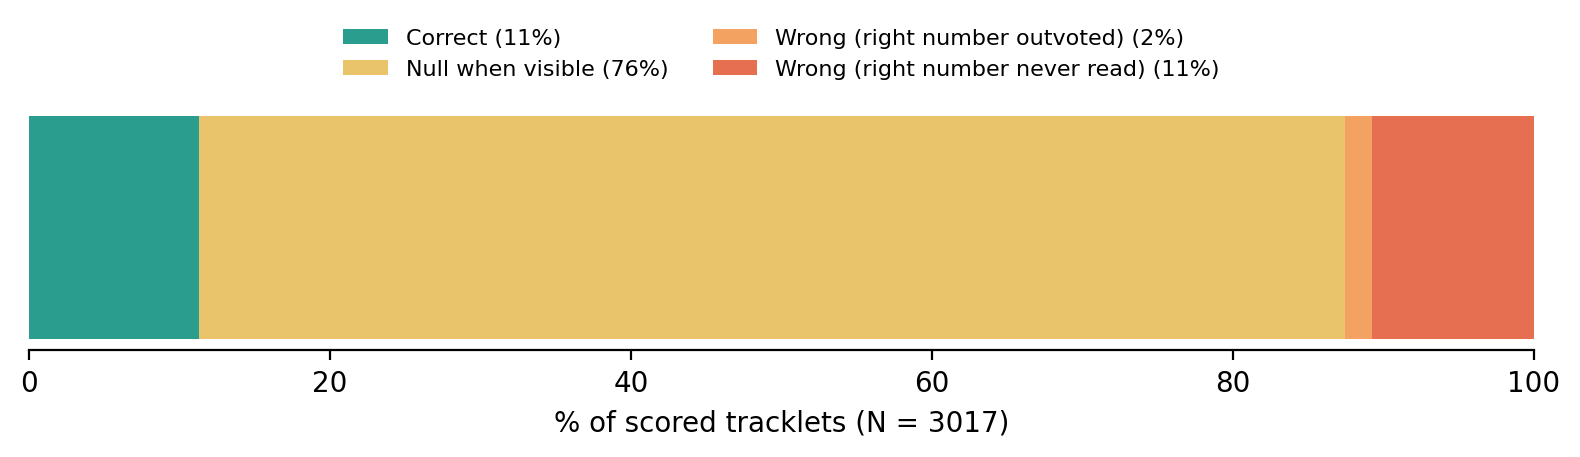

In [17]:
# Show the error-breakdown plot saved by cell 15
from IPython.display import Image, display
display(Image(os.environ['RESULTS'] + '/jersey_mmocr_cached_58/jersey_error_breakdown.png'))

In [22]:
# 16. Wait for the background end-to-end run (cell 10) to finish; prints progress every 2 minutes.
#
# Safe to interrupt and re-run: it only watches the background process, it doesn't control it.
import subprocess, time
RUN = 'fresh_nbjw_5'
log = os.environ['SG_DIR'] + f'/outputs/logs/{RUN}.log'

def running():
    # The TrackLab process has "outputs/runs/fresh_nbjw_5" in its command line.
    return subprocess.run(['pgrep', '-f', f'outputs/runs/{RUN}'], capture_output=True).returncode == 0

while running():
    tail = subprocess.run(['tail', '-c', '400', log], capture_output=True, text=True, errors='replace').stdout
    print(time.strftime('%H:%M'), '|', tail.replace('\n', ' ')[-200:], flush=True)   # last bit of the progress bar
    time.sleep(120)

# Done (or never started): the state file only exists if the run completed.
state = os.environ['SG_DIR'] + f'/outputs/runs/{RUN}/states/sn-gamestate.pklz'
print('Finished.' if os.path.exists(state) else f'No state file found: check {log}')
print(subprocess.run(f"grep -E 'GS-HOTA =' {log} | tail -1", shell=True, capture_output=True, text=True).stdout)

22:40 | ing test transforms ... + resize to 256x128 + to torch tensor of range [0, 1] + normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) + masks preprocess = id + use add background mask 
22:42 | ing test transforms ... + resize to 256x128 + to torch tensor of range [0, 1] + normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) + masks preprocess = id + use add background mask 
22:44 | ing test transforms ... + resize to 256x128 + to torch tensor of range [0, 1] + normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) + masks preprocess = id + use add background mask 
22:46 | ing test transforms ... + resize to 256x128 + to torch tensor of range [0, 1] + normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) + masks preprocess = id + use add background mask 
22:48 | ing test transforms ... + resize to 256x128 + to torch tensor of range [0, 1] + normalization (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) + mask

In [21]:
# How far is the background run (cell 10)? Counts clips already saved in its state file.
import zipfile, os, time
state = os.environ['SG_DIR'] + '/outputs/runs/fresh_nbjw_5/states/sn-gamestate.pklz'
log = os.environ['SG_DIR'] + '/outputs/logs/fresh_nbjw_5.log'
try:
    done = sorted(n[:-4] for n in zipfile.ZipFile(state).namelist()
                  if n.endswith('.pkl') and not n.endswith('_image.pkl'))
    print(f'{len(done)} of {N_CLIPS} clips finished: {done}')
except FileNotFoundError:
    print(f'0 of {N_CLIPS} clips finished (first clip still in progress)')
except zipfile.BadZipFile:
    print('A clip is being saved right now; run this again in a minute.')
print('Log last updated:', time.ctime(os.path.getmtime(log)))

3 of 5 clips finished: ['021', '023', '024']
Log last updated: Wed Oct 21 21:33:02 2026


**17–18. Calibration swap and the 5-clip reference.** SoccerNet's cached state was made with **TVCalib**; our own run uses
**NBJW** calibration (the current default). Cell 17 loads the cached state and re-runs only the calibration steps (pitch,
calibration, team side) with NBJW, keeping detection, tracking and jerseys fixed. Cell 18 scores the unchanged cached state on
the same 5 clips. Together they give three comparable numbers on the same clips:

* cached TVCalib vs. cached NBJW: the effect of calibration alone (our second configuration for item 1c)
* cached NBJW vs. our own run: the reproduction check for item 1b (same modules, so they should be close)

If cell 17 fails, skip it: it was first on the cut list. Cell 18 still gives the cached reference for our run.

In [23]:
%%bash
# 17. Item 1c: calibration swap on the same 5 clips (GPU, ~15-25 min; run after cell 16 so two GPU jobs don't compete)
#
# Overrides used:
#   pipeline=[pitch,calibration,team_side]   re-run only these modules; everything else comes from the cached state
#                                            (team side is re-run because it depends on the new pitch positions)
#   state.save_file=states/recalib.pklz      keep the recalibrated state (inside this run's folder)
# Output: outputs/runs/cached_recalib_nbjw_5/
cd "$SG_DIR"
./run_tl.sh cached_recalib_nbjw_5 'pipeline=[pitch,calibration,team_side]' state.load_file="$SLIM" \
    state.save_file=states/recalib.pklz visualization=none dataset.nvid=-1 "dataset.vids_dict.valid=$CLIPS_HYDRA"

 performance GS-HOTA = 
 INFO Saved state at : main.py:69


In [24]:
%%bash
# 18. Score the unchanged cached state on the same 5 clips (reference for 1b and 1c; ~1 min)
# Needed because a COMBINED score over 5 clips can't be read off the 58-clip run: it has to be computed on those clips.
# Output: outputs/runs/cached_5/
cd "$SG_DIR"
./run_tl.sh cached_5 'pipeline=[]' state.load_file="$SLIM" state.save_file=null visualization=none \
    dataset.nvid=-1 "dataset.vids_dict.valid=$CLIPS_HYDRA"

 performance GS-HOTA = 


**19–20. Tables for the report, and saving.** Cell 19 collects the scores of all runs into two tables (saved as CSV on Drive),
plus jersey accuracy on our own run vs. the cached state for the same 5 clips. The cell after it turns the 58-clip table into
the "floor / baseline / ceiling" sentence for the write-up. Cell 20 copies everything to Drive and saves one video frame from
our own run for the "results are our own" figure.

In [25]:
%%bash
# 19. Tables for the report (CSV copies go to MyDrive/gsr-results/midterm/tables/)
cd "$SG_DIR/outputs/runs"
T="$RESULTS/tables"

# Table 1 (all 58 clips): floor, baseline, ceiling. Items 1a + 1c (jersey).
echo "################ Table 1: all 58 validation clips (items 1a + 1c jersey) ################"
"$PY" "$TOOLS" results nojersey_58 cached_58 oracle_58 oracle_frame_58 \
      --names no_jersey baseline_mmocr oracle oracle_frame --out-dir "$T" --prefix all58 | sed -n '1,7p'
echo

# Table 2 (our 5 clips): calibration effect and reproduction check, overall and per clip. Items 1b + 1c (calibration).
echo "################ Table 2: our 5 clips (items 1b + 1c calibration) ################"
"$PY" "$TOOLS" results cached_5 cached_recalib_nbjw_5 fresh_nbjw_5 \
      --names cached_tvcalib cached_nbjw own_run_nbjw --out-dir "$T" --prefix five_clips
echo

# Jersey accuracy on our own run vs. the cached state, same 5 clips (only the headline lines are printed;
# full reports are on Drive in jersey_mmocr_own_5/ and jersey_mmocr_cached_5/).
echo "################ Jersey accuracy on our own run vs cached, same 5 clips ################"
"$PY" "$TOOLS" jersey-acc fresh_nbjw_5/states/sn-gamestate.pklz --gt-dir "$GT_DIR" --out-dir "$RESULTS/jersey_mmocr_own_5" | sed -n '4,6p'
"$PY" "$TOOLS" jersey-acc "$SLIM" --gt-dir "$GT_DIR" --clips $CLIPS --out-dir "$RESULTS/jersey_mmocr_cached_5" | sed -n '4,6p'

################ Table 1: all 58 validation clips (items 1a + 1c jersey) ################
Overall (COMBINED over each run's clips)
                GS-HOTA   DetA   AssA  clips
no_jersey         13.14   4.30  40.30     58
baseline_mmocr    18.85   7.95  44.73     58
oracle            29.31  20.38  42.18     58
oracle_frame      29.11  21.29  39.86     58


################ Table 2: our 5 clips (items 1b + 1c calibration) ################
Overall (COMBINED over each run's clips)
                GS-HOTA   DetA   AssA  clips
cached_tvcalib    23.54  12.77  43.45      5
cached_nbjw       31.18  20.01  48.64      5
own_run_nbjw      27.69  15.99  47.96      5

GS-HOTA per clip
          cached_tvcalib  cached_nbjw  own_run_nbjw
seq                                                
SNGS-021           24.17        41.15         38.37
SNGS-022           10.31        30.91         23.70
SNGS-023           25.07        21.33         18.66
SNGS-024           11.87        23.70         29.33
SNGS-025

In [26]:
# Headroom summary for the write-up: where the MMOCR baseline sits between the floor (no jerseys) and the ceiling (oracle).
import pandas as pd
t = pd.read_csv(os.environ['RESULTS'] + '/tables/all58_overall.csv', index_col=0)
lo, base, hi = t.loc['no_jersey', 'GS-HOTA'], t.loc['baseline_mmocr', 'GS-HOTA'], t.loc['oracle', 'GS-HOTA']
print(f"GS-HOTA  no-jersey {lo:.2f} | MMOCR baseline {base:.2f} | oracle {hi:.2f}")
print(f"MMOCR adds {base - lo:+.2f} points over no jersey; perfect tracklet-level jerseys would add {hi - base:+.2f} more.")
# Share of the achievable jersey gain that MMOCR already captures: (baseline - floor) / (ceiling - floor)
print(f"MMOCR captures {100 * (base - lo) / (hi - lo):.0f}% of the gain available from jersey recognition.")
if 'oracle_frame' in t.index:
    print(f"Per-frame oracle {t.loc['oracle_frame', 'GS-HOTA']:.2f}: the extra over the tracklet oracle is what ID switches cost jersey assignment.")

GS-HOTA  no-jersey 13.14 | MMOCR baseline 18.85 | oracle 29.31
MMOCR adds +5.71 points over no jersey; perfect tracklet-level jerseys would add +10.46 more.
MMOCR captures 35% of the gain available from jersey recognition.
Per-frame oracle 29.11: the extra over the tracklet oracle is what ID switches cost jersey assignment.


In [27]:
%%bash
# 20. Save everything to Drive: run outputs (eval results, logs, our run's state and videos) and a report frame
#
# Saved under MyDrive/gsr-results/midterm/:
#   runs/<name>/results/   scores of every run (small)
#   runs/fresh_nbjw_5/     our run's state (2 h of GPU work; cell 10 restores it next session) and, if SAVE_VIDEOS, its videos
#   logs/                  full TrackLab logs
#   figures/               one frame from our own run's output video
cd "$SG_DIR/outputs"
mkdir -p "$RESULTS/runs" "$RESULTS/logs" "$RESULTS/figures"
for r in runs/*; do
  name=$(basename "$r")
  mkdir -p "$RESULTS/runs/$name"
  cp -r "$r/eval/results" "$RESULTS/runs/$name/" 2>/dev/null
done
cp -r runs/fresh_nbjw_5/states "$RESULTS/runs/fresh_nbjw_5/" 2>/dev/null   # our run's state (2 h of GPU work)
if [ "$SAVE_VIDEOS" = 1 ]; then cp -r runs/fresh_nbjw_5/visualization "$RESULTS/runs/fresh_nbjw_5/" 2>/dev/null; fi
cp logs/*.log "$RESULTS/logs/"
# One frame (12 s in) from our own run for the report ("results are our own")
vid=$(ls runs/fresh_nbjw_5/visualization/videos/*.mp4 2>/dev/null | head -1)
if [ -n "$vid" ]; then
  ffmpeg -loglevel error -y -ss 00:00:12 -i "$vid" -frames:v 1 "$RESULTS/figures/own_run_frame.png" && echo "Saved frame from $vid"
fi
#du -sh "$RESULTS"/*   # how much Drive space the results use

Saved frame from runs/fresh_nbjw_5/visualization/videos/SNGS-021.mp4


bash: line 23: -sh: command not found


CalledProcessError: Command 'b'# 20. Save everything to Drive: run outputs (eval results, logs, our run\'s state and videos) and a report frame\n#\n# Saved under MyDrive/gsr-results/midterm/:\n#   runs/<name>/results/   scores of every run (small)\n#   runs/fresh_nbjw_5/     our run\'s state (2 h of GPU work; cell 10 restores it next session) and, if SAVE_VIDEOS, its videos\n#   logs/                  full TrackLab logs\n#   figures/               one frame from our own run\'s output video\ncd "$SG_DIR/outputs"\nmkdir -p "$RESULTS/runs" "$RESULTS/logs" "$RESULTS/figures"\nfor r in runs/*; do\n  name=$(basename "$r")\n  mkdir -p "$RESULTS/runs/$name"\n  cp -r "$r/eval/results" "$RESULTS/runs/$name/" 2>/dev/null\ndone\ncp -r runs/fresh_nbjw_5/states "$RESULTS/runs/fresh_nbjw_5/" 2>/dev/null   # our run\'s state (2 h of GPU work)\nif [ "$SAVE_VIDEOS" = 1 ]; then cp -r runs/fresh_nbjw_5/visualization "$RESULTS/runs/fresh_nbjw_5/" 2>/dev/null; fi\ncp logs/*.log "$RESULTS/logs/"\n# One frame

In [ ]:
%%bash
# 21. (Optional) Cache the environment, weights and 5 clips to Drive for faster future sessions.
#     Uses ~7 GB of Drive. Skip it if your Drive is nearly full; nothing above depends on it.
CACHE=/content/drive/MyDrive/gsr-cache
mkdir -p $CACHE
cd /content/soccer-trajectory-prediction/third_party/sn-gamestate

# The Python 3.9 environment, plus the Python interpreter uv downloaded (the env depends on it)
tar -cf $CACHE/venv.tar .venv
tar -cf $CACHE/uv-python.tar -C /root/.local/share/uv python

# Model weights downloaded on the first run
[ -d pretrained_models ] && tar -cf $CACHE/weights.tar pretrained_models

# A small dev subset of validation clips (the first 5), so you don't need the full 10 GB
cd /content/soccer-trajectory-prediction/data/SoccerNetGS
mkdir -p $CACHE/valid5 && for v in $(ls valid | head -5); do cp -r valid/$v $CACHE/valid5/; done

du -sh $CACHE/*